# Operating Window - which combined X range makes BOTH Viscosity and Kappa most capable (Cpk)

**Idea:** Capability -> Operating Window -> Critical X Combination.
We score **two Y together** - Viscosity (`CAP_SPEC` = 700-800, target 750) and Kappa (`CAP_SPEC2` = 9-11, target 10) -
inside boxes made by quantile-binning several X at once, and find the combination with the best **Cpk_min**.

`Cpk_min = min(Cpk_viscosity, Cpk_kappa)` -> a window only wins if it is good for **both** Y (they often trade off).

| Step | What | Why |
|---|---|---|
| 0 | Baseline Cpk (both Y) over all batches | the number any window must beat |
| 0.5 | Baseline Cpk by digester (D1-D4) | is the spread a "which pot" effect? |
| 1 | Per-X Cpk by bin (both Y) | quick look: does one X alone move Cpk? |
| 2 | Grid search of X combinations | the Critical X Combination (ranked by Cpk_min) |
| 3 | Inside vs outside the best window | does the window really win for both Y? |

**X tested (`CAP_X`, 5):** P-factor overshoot, Alkali conc 1, Prehyd minutes, Chip weight, **Digester** (categorical,
split by its 4 pots instead of quantiles). **Edit `config.py`** (section *Capability / Operating Window*) to change
X, specs, bins, combo size, min N.

`Cpk = min((USL-mean), (mean-LSL)) / 3sd`. It assumes each Y is roughly normal in the box; skew is flagged.
Boxes with `N < CAP_MIN_N` are dropped (small-sample Cpk is noise). No PI access - reads batch_master.csv.
Trip outliers of X are dropped first in `load_golden()` (`config.X_VALID_RANGE`: P-factor overshoot <= 134,
Prehyd minutes <= 100), so box edges are not stretched by runaway batches.

In [58]:
import importlib
import pandas as pd

import config, data, golden, capability as cap
for mod in (config, data, golden, cap):
    importlib.reload(mod)

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 40)

## Step 0 - Baseline capability
Cpk of **Viscosity and Kappa** over every batch, plus `Cpk_min`. This is the bar the operating window must beat.

In [59]:
df = golden.load_golden()
_ = cap.baseline(df)

golden data: 760 batches with Kappa + Viscosity (2026-05-09 .. 2026-10-18), golden 309 (41%)
baseline: N=760  Viscosity mean=774.7 Cpk=0.20 (spec 700-800)  |  Kappa mean=10.1 Cpk=0.32 (spec 9-11)  |  Cpk_min=0.20


## Step 0.5 - Capability by digester
Cpk of Viscosity and Kappa per digester (D1-D4) vs overall. If the pots differ a lot, the spread is a "which pot"
effect and each pot may need its own window; if they are close, the pooled analysis below is fine.

In [60]:
dg = cap.baseline_by_digester(df)
display(dg.round({"mean": 1, "std": 1, "cpk": 2, "cp": 2}))

baseline by digester (Viscosity 700-800, Kappa 9-11):


,digester,n,visc_mean,cp_visc,cpk_visc,kappa_mean,cp_kappa,cpk_kappa,cp_min,cpk_min
0,1,213,770.84,0.44,0.26,9.88,0.36,0.32,0.36,0.26
1,2,216,773.16,0.35,0.19,10.22,0.40,0.31,0.35,0.19
2,3,225,779.76,0.37,0.15,10.16,0.38,0.32,0.37,0.15
3,4,106,774.90,0.49,0.25,10.33,0.36,0.24,0.36,0.24
4,ALL,760,774.71,0.39,0.20,10.12,0.37,0.32,0.37,0.20


## Step 1 - One X at a time
Cpk of **Viscosity and Kappa** per quantile bin of each X. If a single X already moves either Cpk a lot, it will
matter in the combo. Digester is split by its 4 pots (not quantiles).

In [61]:
for x, tbl in cap.bin_tables(df).items():
    display(tbl.round({"mean": 1, "std": 1, "cpk": 2, "cp": 2}))

,x,range,n,visc_mean,cp_visc,cpk_visc,kappa_mean,cp_kappa,cpk_kappa,cp_min,cpk_min
0,P-factor overshoot,25.92-62.10,254,788.44,0.37,0.09,10.33,0.38,0.26,0.37,0.09
1,P-factor overshoot,62.10-75.19,253,770.04,0.44,0.26,10.05,0.39,0.37,0.39,0.26
2,P-factor overshoot,75.19-133.86,253,765.58,0.42,0.29,9.98,0.36,0.35,0.36,0.29


,x,range,n,visc_mean,cp_visc,cpk_visc,kappa_mean,cp_kappa,cpk_kappa,cp_min,cpk_min
0,Alkali conc 1,34.78-36.48,254,797.35,0.40,0.02,10.06,0.38,0.35,0.38,0.02
1,Alkali conc 1,36.48-37.07,253,769.32,0.48,0.29,10.09,0.36,0.33,0.36,0.29
2,Alkali conc 1,37.07-38.77,253,757.35,0.42,0.36,10.22,0.38,0.29,0.38,0.29


,x,range,n,visc_mean,cp_visc,cpk_visc,kappa_mean,cp_kappa,cpk_kappa,cp_min,cpk_min
0,Prehyd minutes,56.08-75.07,254,764.15,0.50,0.36,9.86,0.39,0.34,0.39,0.34
1,Prehyd minutes,75.07-83.63,253,787.64,0.40,0.10,10.20,0.34,0.28,0.34,0.10
2,Prehyd minutes,83.63-110.00,253,772.37,0.35,0.20,10.31,0.41,0.28,0.35,0.20


,x,range,n,visc_mean,cp_visc,cpk_visc,kappa_mean,cp_kappa,cpk_kappa,cp_min,cpk_min
0,Chip weight,50.01-84.64,254,774.05,0.44,0.23,10.16,0.37,0.31,0.37,0.23
1,Chip weight,84.64-91.98,253,775.85,0.39,0.19,10.01,0.37,0.37,0.37,0.19
2,Chip weight,91.98-112.58,253,774.22,0.37,0.19,10.21,0.38,0.30,0.37,0.19


,x,range,n,visc_mean,cp_visc,cpk_visc,kappa_mean,cp_kappa,cpk_kappa,cp_min,cpk_min
0,Digester,1,213,770.84,0.44,0.26,9.88,0.36,0.32,0.36,0.26
1,Digester,2,216,773.16,0.35,0.19,10.22,0.40,0.31,0.35,0.19
2,Digester,3,225,779.76,0.37,0.15,10.16,0.38,0.32,0.37,0.15
3,Digester,4,106,774.90,0.49,0.25,10.33,0.36,0.24,0.36,0.24


,x,range,n,visc_mean,cp_visc,cpk_visc,kappa_mean,cp_kappa,cpk_kappa,cp_min,cpk_min
0,P-temp SP,162.00-163.00,317,792.74,0.38,0.06,10.40,0.38,0.23,0.38,0.06
1,P-temp SP,163.00-164.00,115,751.16,0.48,0.47,10.10,0.39,0.35,0.39,0.35
2,P-temp SP,164.00-166.00,115,755.72,0.54,0.48,9.84,0.45,0.38,0.45,0.38


สรุป cpk ที่ดี
P-factor overshoot	62.6-76.4, Alkali conc 1	37.1-38.8	


## Step 2 - Critical X Combination (grid search)
Every combination of `CAP_COMBO_SIZE` X, each numeric X split into `CAP_BINS` quantile bins (Digester split by pot).
Ranked by **Cpk_min** (the window must be good for both Y), boxes with `N >= CAP_MIN_N` only.
Top row = the window where both Viscosity and Kappa are most capable at once.

In [62]:
res = cap.search(df)
display(cap.summary(res, 20))

search: 137 boxes with N >= 15  (combo size 2, 3 bins/X, ranked by cp_min)


,combo,P-factor overshoot,Alkali conc 1,Prehyd minutes,Chip weight,Digester,P-temp SP,n,cp_kappa,cp_visc,cpk_kappa,cpk_visc,cp_min,cpk_min
0,Digester x P-temp SP,-,-,-,-,3,164.00-166.00,55,0.56,0.72,0.44,0.61,0.56,0.44
1,Prehyd minutes x Digester,-,-,56.08-75.07,-,3,-,73,0.56,0.62,0.49,0.50,0.56,0.49
2,Prehyd minutes x P-temp SP,-,-,56.08-75.07,-,-,163.00-164.00,27,0.52,0.67,0.39,0.60,0.52,0.39
3,P-factor overshoot x P-temp SP,62.10-75.19,-,-,-,-,163.00-164.00,43,0.49,0.50,0.46,0.46,0.49,0.46
4,P-factor overshoot x P-temp SP,75.19-133.86,-,-,-,-,164.00-166.00,51,0.49,0.58,0.35,0.49,0.49,0.35
5,Chip weight x P-temp SP,-,-,-,84.64-91.98,-,163.00-164.00,27,0.48,0.70,0.36,0.63,0.48,0.36
6,P-factor overshoot x Prehyd minutes,75.19-133.86,-,56.08-75.07,-,-,-,106,0.47,0.53,0.33,0.45,0.47,0.33
7,Chip weight x P-temp SP,-,-,-,84.64-91.98,-,164.00-166.00,57,0.47,0.55,0.38,0.53,0.47,0.38
8,Alkali conc 1 x P-temp SP,-,36.48-37.07,-,-,-,164.00-166.00,74,0.47,0.50,0.40,0.47,0.47,0.40
9,Prehyd minutes x P-temp SP,-,-,56.08-75.07,-,-,164.00-166.00,103,0.47,0.58,0.40,0.49,0.47,0.40


## Step 2b - Sensitivity (slide one X)
Take the best box, **hold three X fixed** at their chosen range and **slide the fourth** across every bin it really took. One block per X: the X whose `cp_min` drops the most when moved is the most **critical**; one that barely changes has a wide safe range. Rows flagged `small-n` have N < `CAP_MIN_N` (Cp is noise).

In [63]:
display(cap.sensitivity(df, res, rank=0))

sensitivity around rank 0: Digester x P-temp SP  (hold 3, slide 1; index marks the slid X)


,P-factor overshoot,Alkali conc 1,Prehyd minutes,Chip weight,Digester,P-temp SP,n,cp_kappa,cp_visc,cpk_kappa,cpk_visc,cp_min,cpk_min
Digester,-,-,-,-,2,164.00-166.00,48,0.41,0.44,0.37,0.41,0.41,0.37
Digester < chosen,-,-,-,-,3,164.00-166.00,55,0.56,0.72,0.44,0.61,0.56,0.44
Digester small-n,-,-,-,-,4,164.00-166.00,12,0.34,0.55,0.28,0.50,0.34,0.28
P-temp SP,-,-,-,-,3,162.00-163.00,127,0.35,0.38,0.21,-0.00,0.35,-0.00
P-temp SP,-,-,-,-,3,163.00-164.00,43,0.44,0.51,0.41,0.47,0.44,0.41
P-temp SP < chosen,-,-,-,-,3,164.00-166.00,55,0.56,0.72,0.44,0.61,0.56,0.44


## Step 2c - Timeline (when did this box run?)
Splits the box's batches into **bursts** (a gap > 7 days starts a new burst). Many bursts spread across months = the X window repeats and is trustworthy; one tight burst in a single month = the result may be a calendar artifact (time confounder), not an X effect.

In [64]:
display(cap.timeline(df, res, rank=0))

timeline rank 0: Digester 3, P-temp SP 164.00-166.00
  98 batches in 5 burst(s) over 162 days; busiest month 2026-06 = 42% of batches (gap > 7 d = new burst)


,first,last,span_days,n,cp_kappa,cp_visc,cpk_kappa,cpk_visc,cp_min,cpk_min
burst,,,,,,,,,,
1,2026-05-09,2026-05-13,4,6,0.83,0.53,0.58,0.36,0.53,0.36
2,2026-05-20,2026-07-04,45,68,0.58,0.73,0.42,0.66,0.58,0.42
3,2026-08-29,2026-08-29,0,1,NaN,NaN,NaN,NaN,NaN,NaN
4,2026-09-11,2026-09-22,10,8,0.31,0.58,0.10,0.22,0.31,0.10
5,2026-10-09,2026-10-18,9,15,0.61,0.55,0.46,0.32,0.55,0.32
ALL,2026-05-09,2026-10-18,162,98,0.50,0.59,0.42,0.56,0.50,0.42


## Step 2d - Sweet spot by digester
Do the 4 digesters have different sweet spots? Runs the grid search **inside each digester** 
(digester dropped from the X) and stacks the single best box of each. N per digester is smaller, 
so min_n is lowered - treat the Cp numbers as noisy and cross-check with `timeline`.

In [65]:
display(cap.by_digester(df, top=3))

search: 54 boxes with N >= 7  (combo size 2, 3 bins/X, ranked by cp_min)
search: 83 boxes with N >= 7  (combo size 2, 3 bins/X, ranked by cp_min)
search: 85 boxes with N >= 7  (combo size 2, 3 bins/X, ranked by cp_min)
search: 73 boxes with N >= 7  (combo size 2, 3 bins/X, ranked by cp_min)
by_digester: top 3 box per digester  (digester dropped from X, combo size 2, 3 bins/X, min N 7)


,digester,combo,P-factor overshoot,Alkali conc 1,Prehyd minutes,Chip weight,P-temp SP,n,cp_kappa,cp_visc,cpk_kappa,cpk_visc,cp_min,cpk_min
0,1,Alkali conc 1 x Chip weight,-,37.03-38.13,-,74.53-89.55,NaN,12,0.56,0.84,0.34,0.67,0.56,0.34
1,1,P-factor overshoot x Alkali conc 1,78.35-133.58,34.78-36.45,-,-,NaN,18,0.52,0.60,0.36,0.16,0.52,0.16
2,1,Alkali conc 1 x Chip weight,-,34.78-36.45,-,74.53-89.55,NaN,23,0.43,0.64,0.33,0.22,0.43,0.22
3,2,Chip weight x P-temp SP,-,-,-,80.49-89.60,163.00-164.00,12,0.60,0.68,0.42,0.67,0.60,0.42
4,2,Prehyd minutes x P-temp SP,-,-,56.08-75.24,-,163.00-164.00,15,0.52,0.75,0.30,0.70,0.52,0.30
5,2,Alkali conc 1 x Chip weight,-,34.96-36.49,-,94.98-110.59,-,13,0.50,0.49,0.18,-0.09,0.49,-0.09
6,3,P-factor overshoot x Prehyd minutes,64.14-79.61,-,63.23-75.43,-,-,29,0.70,0.71,0.52,0.59,0.70,0.52
7,3,Prehyd minutes x P-temp SP,-,-,63.23-75.43,-,164.00-166.00,52,0.67,0.72,0.52,0.59,0.67,0.52
8,3,Prehyd minutes x Chip weight,-,-,63.23-75.43,87.41-99.90,-,17,0.63,0.68,0.63,0.51,0.63,0.51
9,4,Alkali conc 1 x Prehyd minutes,-,36.51-37.26,86.77-109.07,-,-,7,0.75,0.88,0.21,0.52,0.75,0.21


## Step 3 - Best window: inside vs outside
Cpk / mean / std / N for **both Y** inside the best box vs the rest. A real window has higher Cpk_min inside.

In [66]:
_ = cap.report(df)

search: 137 boxes with N >= 15  (combo size 2, 3 bins/X, ranked by cp_min)
best window: Digester 3, P-temp SP 164.00-166.00
           n  visc_mean   cp_visc  cpk_visc  kappa_mean  cp_kappa  cpk_kappa    cp_min  cpk_min
inside    98      752.9  0.590326      0.56         9.8  0.500762       0.42  0.500762     0.42
outside  449      781.3  0.370279      0.14        10.3  0.373041       0.26  0.370279     0.14


## Step 7 - Viscosity and Kappa over a time window
Plain time-series of Viscosity and Kappa for batches whose `batch_start` falls in the window below.
Spec bands are shaded (Viscosity 700-800, Kappa 9-11). Edit `T_FROM` / `T_TO` for the period and
`DIGESTER` to pick one digester (1-4) or `None` for all.

8 batches in 2026-05-20 .. 2026-07-04  (D4)


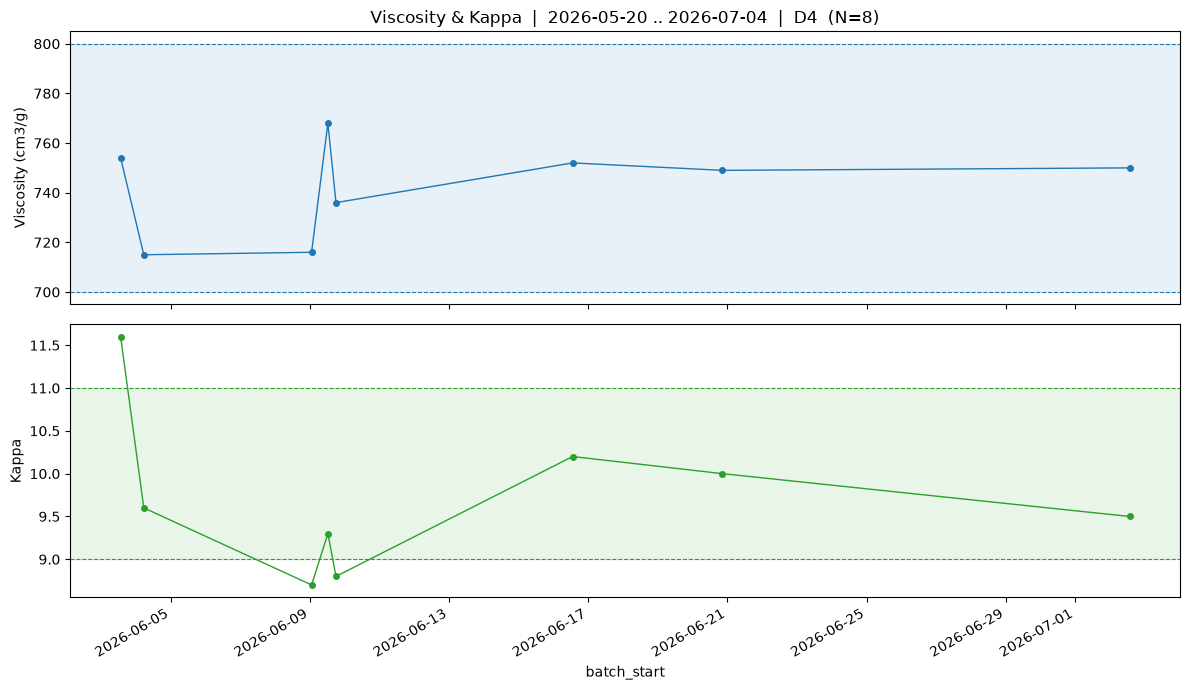

In [77]:
import matplotlib.pyplot as plt

# ---- time window + digester of interest (edit these) ----
T_FROM = "2026-05-20"
T_TO   = "2026-07-04"
DIGESTER = 4            # 1-4 for one digester, or None for all digesters

win = df[df["batch_start"].between(pd.Timestamp(T_FROM), pd.Timestamp(T_TO))]
if DIGESTER is not None:
    win = win[win["digester"] == DIGESTER]
win = win.sort_values("batch_start")
dig_label = f"D{DIGESTER}" if DIGESTER is not None else "all digesters"
print(f"{len(win)} batches in {T_FROM} .. {T_TO}  ({dig_label})")

v_lo, v_hi = config.CAP_SPEC        # Viscosity 700-800
k_lo, k_hi = config.CAP_SPEC2       # Kappa 9-11

fig, (ax_v, ax_k) = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

ax_v.plot(win["batch_start"], win[config.CAP_TARGET], "o-", color="tab:blue", ms=4, lw=1)
ax_v.axhspan(v_lo, v_hi, color="tab:blue", alpha=0.10)
ax_v.axhline(v_lo, color="tab:blue", ls="--", lw=0.8)
ax_v.axhline(v_hi, color="tab:blue", ls="--", lw=0.8)
ax_v.set_ylabel("Viscosity (cm3/g)")
ax_v.set_title(f"Viscosity & Kappa  |  {T_FROM} .. {T_TO}  |  {dig_label}  (N={len(win)})")

ax_k.plot(win["batch_start"], win[config.CAP_TARGET2], "o-", color="tab:green", ms=4, lw=1)
ax_k.axhspan(k_lo, k_hi, color="tab:green", alpha=0.10)
ax_k.axhline(k_lo, color="tab:green", ls="--", lw=0.8)
ax_k.axhline(k_hi, color="tab:green", ls="--", lw=0.8)
ax_k.set_ylabel("Kappa")
ax_k.set_xlabel("batch_start")

fig.autofmt_xdate()
plt.tight_layout()
plt.show()